# A hand-checkable complete pipeline

Constructed illustration, executed with deterministic expectations. The reference is constant 20 °C in 1973–2002; P90 equals the reference, so categories are disabled. The central event has 20 daily patches in four branches, one split and one merge. Two other cells distinguish a cool joined gap from a filled missing observation; a diagonal pair teaches connectivity. No downloaded files are required.

Read [the tutorial guide](../docs/TUTORIALS.md) for inputs, units and configuration. Saved outputs can be read without data. Re-execution requires the optional `examples/requirements.txt`. No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.0.1 |
| Source | synthetic:split-merge-v1 |
| Reference period | 1973-01-01 through 2002-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 11 / 31 |
| Percentile estimator | hyndman_fan_7 |
| Minimum samples | 264 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 5 / 2 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | native |
| Support / spatial dimensions | surface / lat, lon |
| Domain / measure | ocean / area |
| Review status | executed; deterministic expectations checked |

The representative definition is supplemented by the explicitly shown MCS/dynamic or TX/TN joint comparisons where present. Tracking configuration appears in its recipe cell. Full portable specs and checksums are in `report.json` and [the saved run record](../docs/run_records/synthetic.json).


In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
data_dir = Path(os.environ.get("XHW_DATA_DIR", EXAMPLES.parent / "data"))
output_dir = Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "synthetic"

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
from pathlib import Path

import numpy as np
from _data import synthetic_inputs
from _report import spatial_summary, temporal_summary, write_report
from plotting import (
    connectivity_figure,
    frequency_figure,
    genealogy_figure,
    largest_event,
    mask_figure,
    metrics_figure,
    sequence_figure,
    series_figure,
)

import xhw

print(f"Publication API: xHW {xhw.__version__}")

Publication API: xHW 0.0.1


## Prepare a deterministic field and declare its scientific meaning

Input is a temperature Dataset plus explicit grid, baseline and detector specs. Check the grid before computation; the source checksum identifies this constructed field.

In [4]:
raw, grid, baseline, definition = synthetic_inputs()
# Alias of the complete, case-specific definition.
mhw = definition
grid.check(raw)
print("Synthetic surface: constant reference 1973–2002; injected event in January 2003.")

Synthetic surface: constant reference 1973–2002; injected event in January 2003.


## Interpolate one missing temperature; keep its evidence flag

One interior NaN is estimated. The filled flag distinguishes it from observation; filled days do not enter baseline quantiles. A temporal gap is a separate operation.

In [5]:
prepared = xhw.interpolate_gaps(
    raw, variable="sst", grid=grid, max_days=2, max_filled_fraction=0.05
)
assert int(prepared.filled.sum()) == 1

## Fit the baseline and detect per-cell events

BaselineResult separates reference, threshold and sample diagnostics. Detection then produces XMask evidence, and the temporal catalog stores cell-level events.

,start,end,duration_days,intensity_max
event,,,,
0,2003-01-01,2003-01-13,13,5.0
1,2003-01-01,2003-01-13,13,5.0
2,2003-01-01,2003-01-15,15,6.0
3,2003-01-01,2003-01-15,15,6.0
4,2003-01-01,2003-01-15,15,6.0


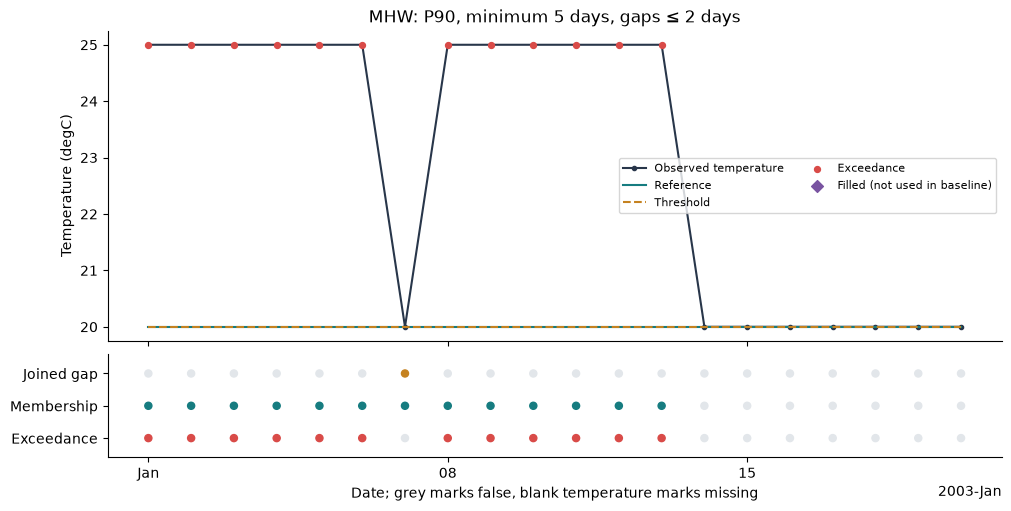

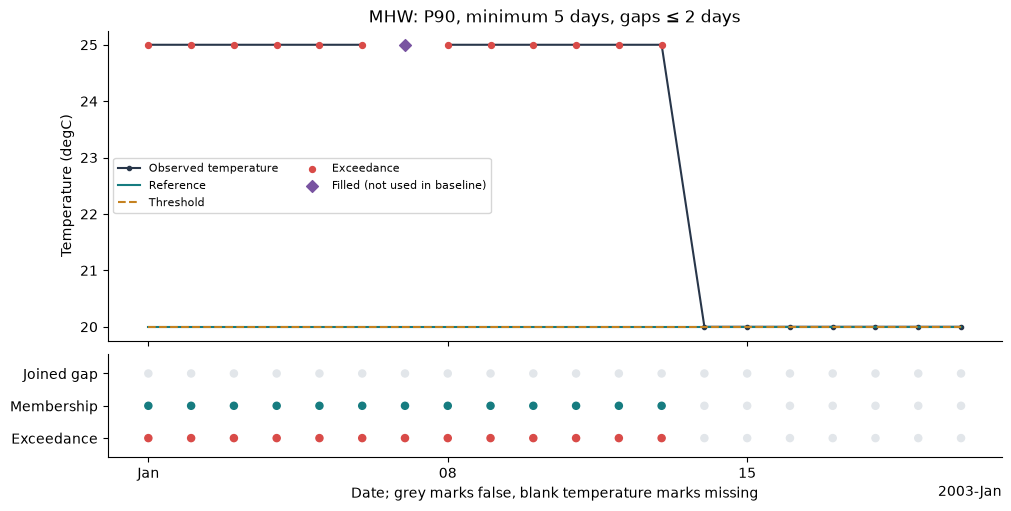

In [6]:
fitted = xhw.fit_baseline(
    prepared, variable="sst", grid=grid, baseline=baseline, definition=mhw
)
fitted.check_invariants()
mask = xhw.detect(
    prepared, variable="sst", grid=grid, definition=mhw, baseline_result=fitted
)
mask.check_invariants()
catalog = xhw.build_catalog(mask, analysis_mode="retrospective")
catalog.check_against(mask)
assert int(mask.dataset.joined_gap.sum()) == 1  # cool day; interpolated hot day exceeds
figure = series_figure(
    raw,
    mask,
    variable="sst",
    selection={"lat": 0, "lon": 0},
    period=("2003-01-01", "2003-01-20"),
    output_dir=output_dir,
)
figure = series_figure(
    raw,
    mask,
    variable="sst",
    selection={"lat": 0, "lon": 8},
    period=("2003-01-01", "2003-01-20"),
    output_dir=output_dir,
    name="missing",
)

catalog.dataset[["start", "end", "duration_days", "intensity_max"]].isel(
    event=slice(0, 5)
).to_dataframe()

**Reading these figures.** Temperature panels show observed values, reference, threshold and exceedances, with separate temporal-membership/gap rows. A diamond identifies a filled value; a gap in the raw line identifies the missing observation. Temperature units appear on the axis. An exceedance is not automatically a persistent event.

## Compare geometry transformations without rewriting temporal evidence

Spatial geometry changes only in a new ObjectField. The original temporal evidence stays intact; added and removed cells record the changes.

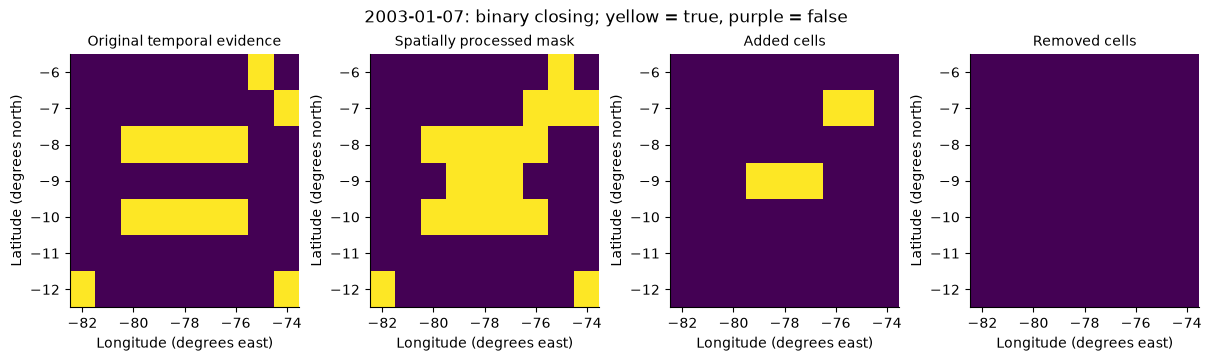

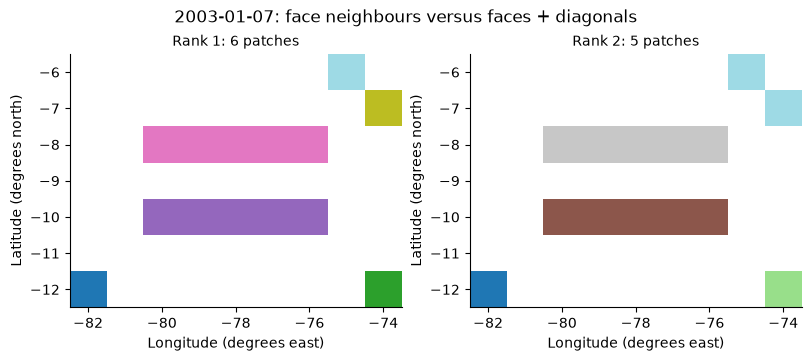

In [7]:
morphology = xhw.SpatialRecipe(
    input_layer="event_membership",
    steps=(
        xhw.RecipeStep.morph("close", footprint=xhw.Footprint.connected(1)),
        xhw.RecipeStep.segment(min_area=xhw.MinArea.none()),
    ),
)
processed = xhw.build_objects(mask, recipe=morphology)
processed.check_invariants()
processed.check_against(mask)
figure = mask_figure(mask, processed, "2003-01-07", output_dir)
figure = connectivity_figure(mask, "2003-01-07", output_dir)

**Reading these figures.** The four geometry panels retain original membership, processed membership, added and removed cells; yellow is true and purple false. Closing can bridge geometry without changing original thermal evidence. The shown removal panel is empty.

On January 7 the diagonal pair has two face-connected labels but one rank-2 label. Connectivity changes connected geometry, not the temperatures.

## Segment daily patches and explicitly track them

Face-connected daily labels restart each day. An explicit final track step links positive shared cells with smaller-object overlap ≥0.1, zero object gaps and five-day minimum tracks. Tracker duration filtering retains daily patch labels.

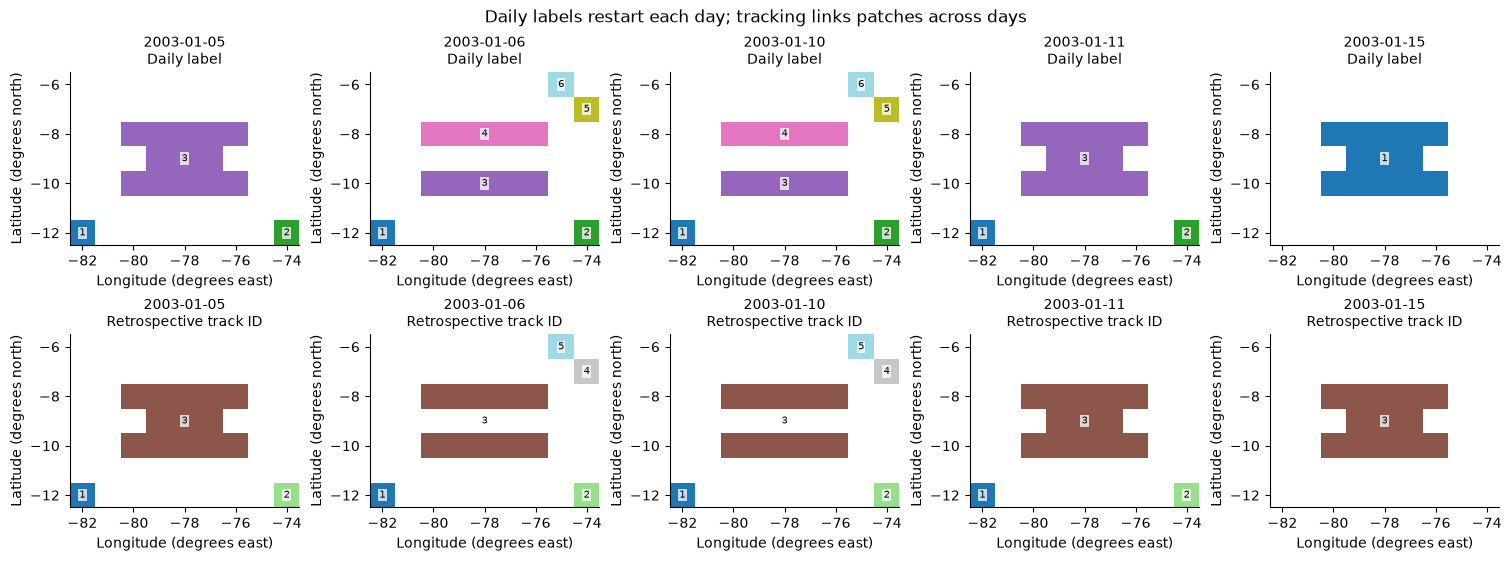

In [8]:
recipe = xhw.SpatialRecipe(
    input_layer="event_membership",
    steps=(
        xhw.RecipeStep.segment(footprint=xhw.Footprint.connected(1), min_area=xhw.MinArea.none()),
        xhw.RecipeStep.track(min_overlap=0.1, max_gap_days=0, min_duration_days=5),
    ),
)
objects = xhw.build_objects(mask, recipe=recipe, analysis_mode="retrospective")
objects.check_invariants()
objects.check_against(mask)
dates = ["2003-01-05", "2003-01-06", "2003-01-10", "2003-01-11", "2003-01-15"]
figure = sequence_figure(objects, dates, output_dir)

**Reading these figures.** Top row: daily labels. Bottom: retrospective tracker IDs, annotated with actual numbers. Background and invalid support are blank; consult the validity mask to distinguish them. IDs are categorical, not magnitudes, and palettes can repeat. For the volume case this is explicitly the first retained depth.

## Genealogy retains all qualifying parents and children

Daily patches are graph nodes. Splits and merges terminate incoming branches and create new branches. The assertions below check manually constructed expectations. Area weights are used for intensity; arrows describe overlap, not causes.

,event_number,event_duration_days,event_n_branches,event_n_splits,event_n_merges
spacetime_event,,,,,
0,1,13,1,0,0
1,2,13,1,0,0
2,3,15,4,1,1
3,4,5,1,0,0
4,5,5,1,0,0


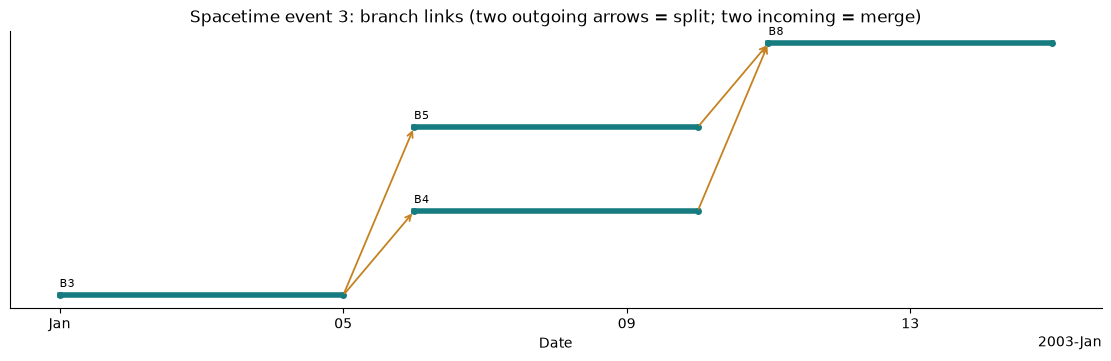

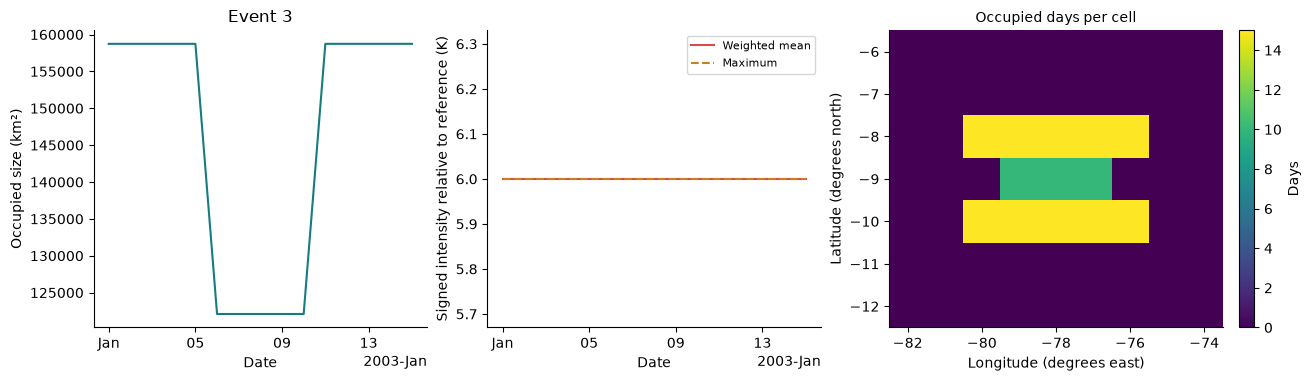

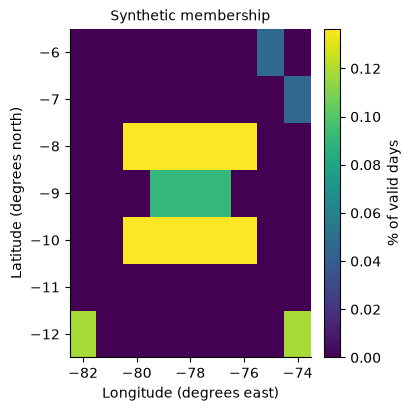

In [9]:
graph = xhw.build_lineage(objects, field=mask.intensity(), weighted=True)
graph.check_invariants()
graph.check_against(objects)
tracked_catalog = graph.to_event_catalog(mask)
graph.check_catalog(tracked_catalog)
event = largest_event(graph)
assert int(graph.dataset.is_split.sum()) == 1
assert int(graph.dataset.is_merge.sum()) == 1
assert graph.members(spacetime_event=event).size == 20  # 5 + 2*5 + 5 daily patches
assert np.unique(graph.dataset.object_branch.values[graph.members(spacetime_event=event)]).size == 4
figure = genealogy_figure(graph, event, output_dir)
figure = metrics_figure(graph, objects, event, output_dir)
frequency_figure({"Synthetic membership": mask}, output_dir)
del figure

graph.dataset[
    ["event_number", "event_duration_days", "event_n_branches", "event_n_splits", "event_n_merges"]
].isel(spacetime_event=slice(0, 5)).to_dataframe()

**Reading these figures.** Teal segments are branches and amber arrows are qualifying parent/child links. Two outgoing links indicate a split; two incoming a merge. Real diagrams mark when only the first 18 branches are displayed. This does not establish causality.

The selected event has size in km² (surface) or km³ (volume), weighted mean and maximum signed intensity relative to reference in K, and occupied days per cell. The volume map is a first-level slice. Peak size, size-time and footprint are different quantities; these figures do not represent all events at once.

Frequency maps show the percentage of occupied valid days, with both numerator and denominator restricted to valid support. Outside-domain cells are blank. Panels have individual scales; compare colorbar values rather than color alone. Differences between methods/profiles are not proof of greater scientific skill.

## Record real execution results and specifications

The report contains versions, exact specs, source checksum, selection, execution time and review status. A reproducible number is not automatically a reviewed scientific conclusion.

In [10]:
metrics = {
    "temporal": temporal_summary(mask, catalog),
    "spatial": spatial_summary(objects, graph),
    "main_event_daily_patches": int(graph.members(spacetime_event=event).size),
    "morphology_added_cell_days": int(processed.dataset.added.sum()),
}
report = write_report(
    output_dir,
    "synthetic",
    metrics,
    grid=grid,
    baseline=baseline,
    definition=mhw,
    recipe=recipe,
    graph=graph,
    review="executed; deterministic expectations checked",
    extra={
        "selection": "1973-01-01 to 2003-01-31; 7 x 9 surface",
        "expected_main_event": "20 patches, 4 branches, 1 split, 1 merge",
    },
)

{
  "temporal": {
    "events": 20,
    "exceedance_cell_days": 215,
    "event_cell_days": 216,
    "joined_cell_days": 1,
    "valid_cell_days": 692244,
    "filled_cell_days": 1,
    "max_duration_days": 15
  },
  "spatial": {
    "patches": 56,
    "tracks": 5,
    "branches": 8,
    "spacetime_events": 5,
    "splits": 1,
    "merges": 1,
    "max_size": 158736510356.7149,
    "size_units": "m2",
    "max_size_time": 2197868682596.9768,
    "max_duration_days": 15
  },
  "main_event_daily_patches": 20,
  "morphology_added_cell_days": 25
}


## Interpretation and provenance

Inspect the executed report and [metrics guide](../docs/METRICS.md). Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. Figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [11]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'executed; deterministic expectations checked',
 'versions': {'xhw': '0.0.1',
  'numpy': '2.5.4',
  'xarray': '2026.7.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:0ec2c2e559a198f355f6f6c4b8c5eb2d8d3d559c79f99609341854334e5bd9dd'}

## Evolution through a split and merge

The same patch/track ID uses the same colour throughout the GIF. Daily labels restart;
track IDs follow overlap. This animation is a view of computed products, not transport
or causal attribution. It has 20 daily frames, three frames per second.


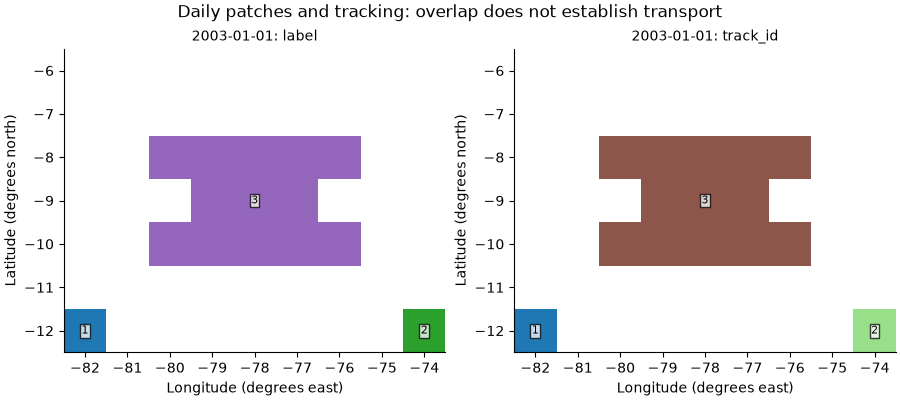

In [12]:
from exploration import objects_gif
from IPython.display import Image, display

animation_path = objects_gif(objects, output_dir, dates=mask.dataset.time.sel(
    time=slice("2003-01-01", "2003-01-20")).values)

display(Image(filename=str(animation_path)))
